# 04 · Port operations and delay risk

**Questions:** How do port operating conditions behave (per port, over time)? How do they relate to each other
(equipment → throughput, labour → congestion)? And which conditions **at the origin / destination, observed before
departure**, are associated with higher delay risk?

Shipment-linked port features are taken from `features.build_shipment_features()`: the port's telemetry at the last hour
≤ `departure_ts − 1 h`, plus trailing-24 h aggregates. No telemetry after the cutoff is used (see notebook 08/09).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as ss

from cargomind_eda import io, stats, features, plotting as P
from cargomind_eda.config import CLASSES, CLASS_COLORS

P.setup()
T = io.load_all()
tel, dis, meta = T["port_hourly_telemetry"], T["disruption_events"], T["port_metadata"]
METRICS = ["throughput_teu", "port_utilization_pct", "container_dwell_hours", "vessel_time_in_port_hours",
           "vessel_arrivals", "vessel_departures", "vessels_at_anchor", "customs_hold_hours", "equipment_availability_pct"]

## D1. Port operating profiles

In [2]:
prof = tel.groupby("port_id")[METRICS].median().join(meta.set_index("port_id")["capacity_teu_per_hour"])
prof["pct_hours_util_100"] = tel.groupby("port_id").port_utilization_pct.apply(lambda x: (x == 100).mean() * 100)
prof["pct_hours_labour_not_normal"] = tel.groupby("port_id").labour_status.apply(lambda x: (x != "normal").mean() * 100)
prof["p95_vessels_at_anchor"] = tel.groupby("port_id").vessels_at_anchor.quantile(0.95)
P.save_table(prof, "04_port_profiles")
prof.round(1).sort_values("container_dwell_hours")

,throughput_teu,port_utilization_pct,container_dwell_hours,vessel_time_in_port_hours,vessel_arrivals,vessel_departures,vessels_at_anchor,customs_hold_hours,equipment_availability_pct,capacity_teu_per_hour,pct_hours_util_100,pct_hours_labour_not_normal,p95_vessels_at_anchor
port_id,,,,,,,,,,,,,
MYPKG,949.2,63.3,67.8,23.3,2,2,0,14.3,92.8,"1,500",1.1,14.2,2
DEHAM,787.2,82,68.4,23.4,1,1,0,12.8,93,960,9.3,12,2
INMAA,145,80.6,69.4,23.2,0,0,0,14.2,93,180,5.2,14,2
SGSIN,"3,446",80.1,77.9,23.9,7,7,0,14,92.8,"4,300",19.9,14.6,7
CNSHA,"3,953",70.6,79.6,26.9,9,8,2,16.2,92.9,"5,600",19.2,22.6,12
INNSA,499,76.8,82.7,24.9,1,1,1,13.8,92.9,650,19.7,10,7
USLAX,819.6,74.5,92.2,24.6,2,1.5,1,14.2,93,"1,100",21.9,9.3,10
AEJEA,"1,136",66.8,105.3,23,3,3,0,14,93.1,"1,700",6.6,4.9,2
LKCMB,726.4,80.7,106.7,23.7,1,1,0,14.6,93,900,19,9.7,5


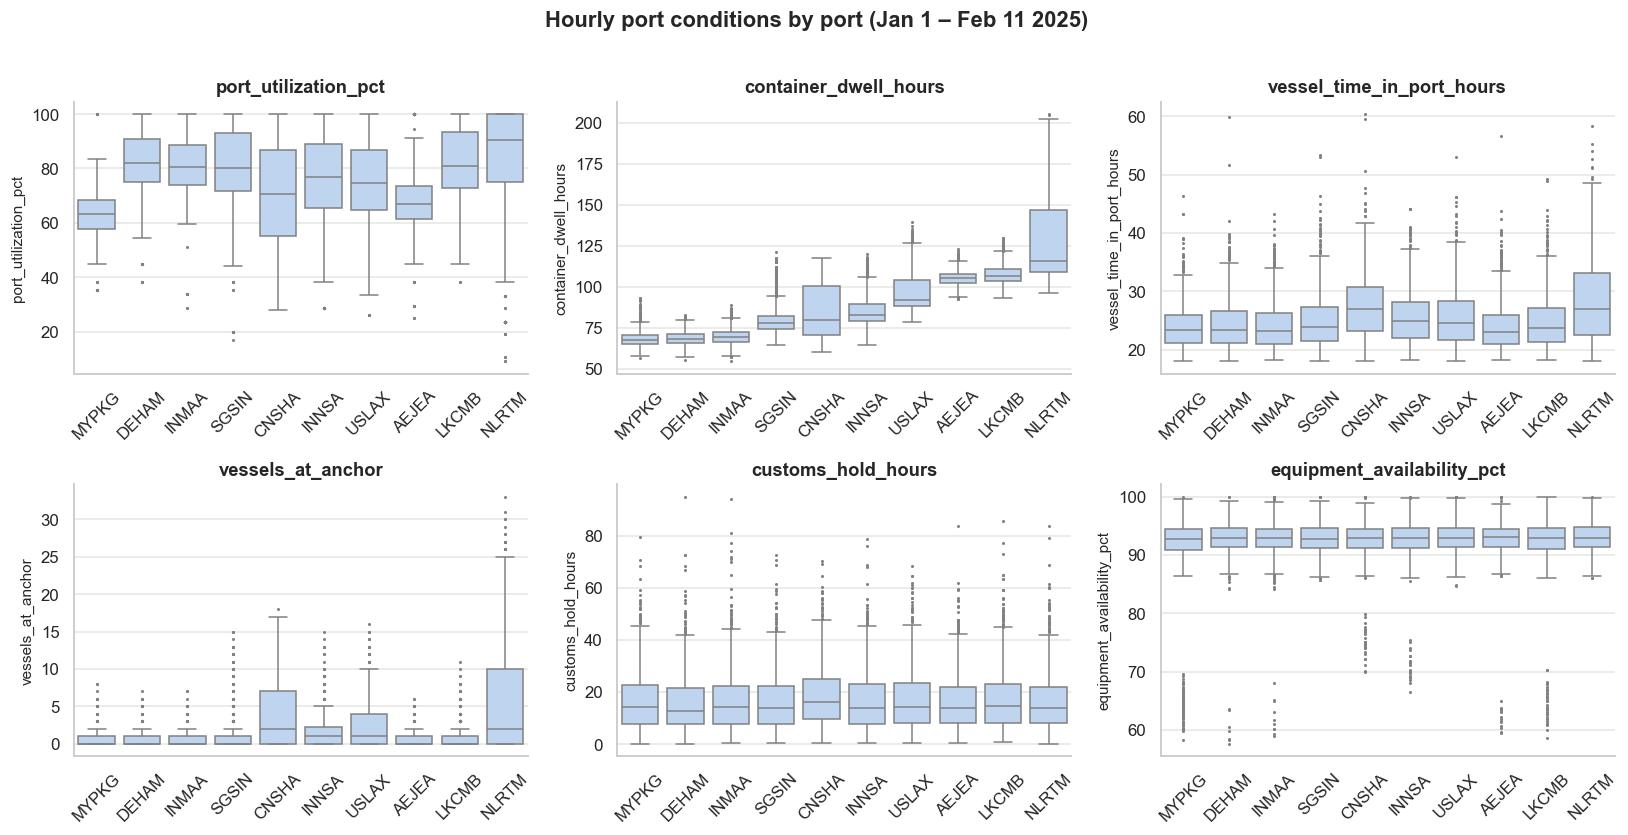

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
order = prof.sort_values("container_dwell_hours").index
for ax, c in zip(axes.flat, ["port_utilization_pct", "container_dwell_hours", "vessel_time_in_port_hours", "vessels_at_anchor", "customs_hold_hours", "equipment_availability_pct"]):
    sns.boxplot(data=tel, x="port_id", y=c, order=order, ax=ax, color="#b7d3f6", fliersize=1, linewidth=1)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.set_title(c)
fig.suptitle("Hourly port conditions by port (Jan 1 – Feb 11 2025)", y=1.01, fontweight="semibold")
P.save(fig, "04_port_condition_distributions")

Ports differ structurally (NLRTM, LKCMB and AEJEA have long dwell; NLRTM sits at 100 % utilization 41 % of the time;
MYPKG and INMAA rarely saturate). Because of these level differences, **pooled** correlations mix between-port and
within-port variation; relationships below are therefore also computed **within port** (each metric centred on its port mean).

## D2. How port metrics relate to each other

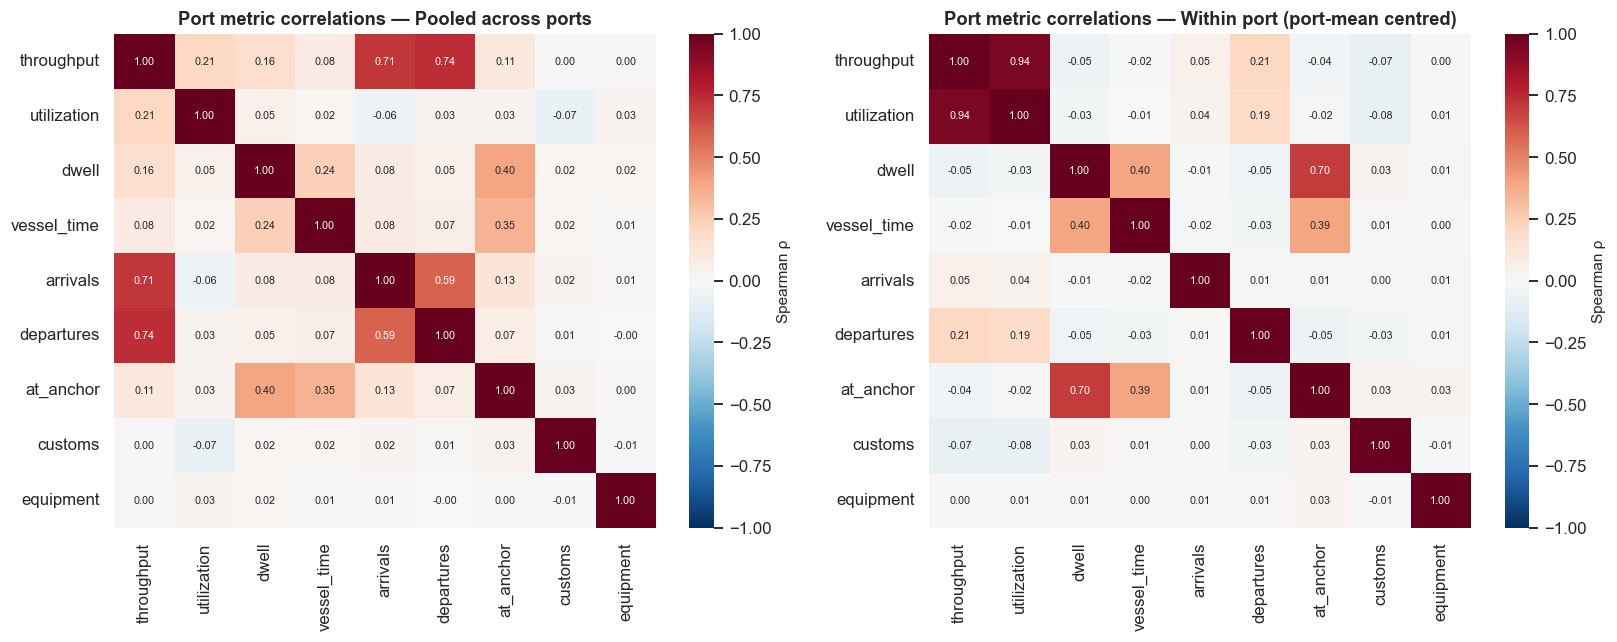

In [4]:
within = tel.copy()
within[METRICS] = within.groupby("port_id")[METRICS].transform(lambda x: x - x.mean())
pooled_r = tel[METRICS].corr("spearman")
within_r = within[METRICS].corr("spearman")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
short = ["throughput", "utilization", "dwell", "vessel_time", "arrivals", "departures", "at_anchor", "customs", "equipment"]
for ax, r, t in [(axes[0], pooled_r, "Pooled across ports"), (axes[1], within_r, "Within port (port-mean centred)")]:
    sns.heatmap(r, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
                xticklabels=short, yticklabels=short, cbar_kws={"label": "Spearman ρ"})
    ax.set_title(f"Port metric correlations — {t}")
P.save(fig, "04_metric_correlations")

### Equipment availability vs throughput, labour vs congestion

/var/folders/75/zcl7vfx51p99nhkfmp7v8vj80000gn/T/ipykernel_37345/2787755007.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  eq_r = tel.groupby("port_id").apply(lambda g: ss.spearmanr(g.equipment_availability_pct, g.port_utilization_pct)[0])


per-port Spearman(equipment, utilization):
 port_id
AEJEA   -0.05
CNSHA   -0.02
DEHAM   -0.01
INMAA    0.02
INNSA   -0.03
LKCMB    0.13
MYPKG   -0.01
NLRTM    0.02
SGSIN    0.03
USLAX    0.03


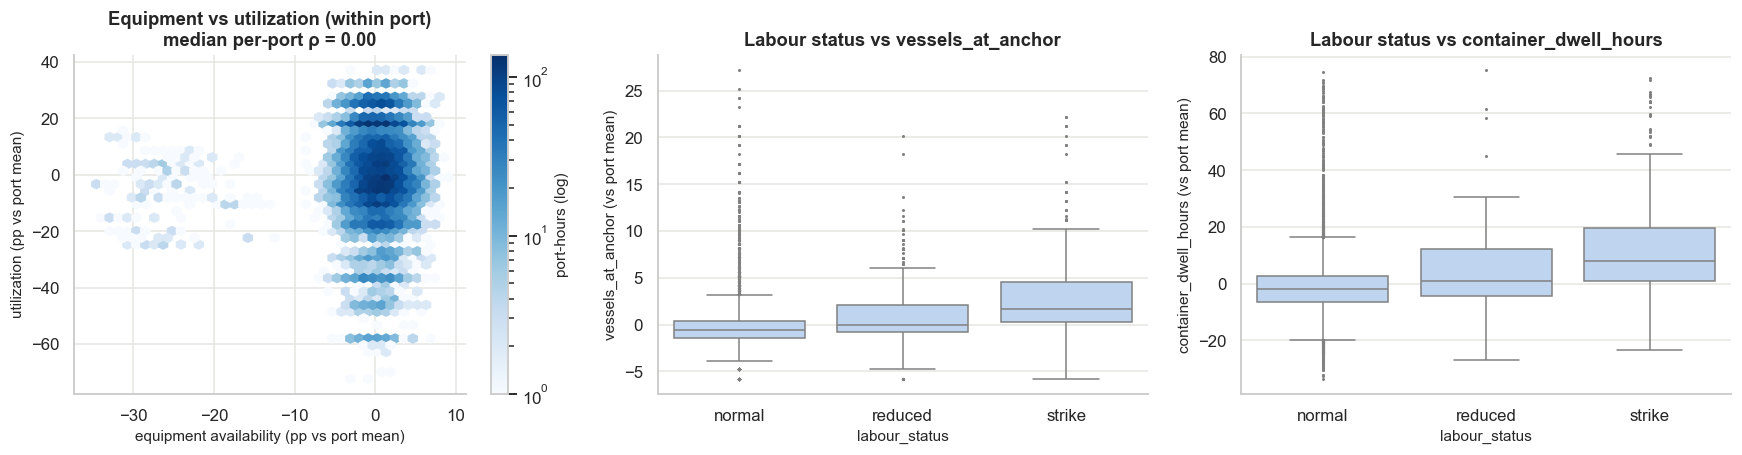

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
eq_r = tel.groupby("port_id").apply(lambda g: ss.spearmanr(g.equipment_availability_pct, g.port_utilization_pct)[0])
hb = axes[0].hexbin(within.equipment_availability_pct, within.port_utilization_pct, gridsize=40, cmap="Blues", mincnt=1, bins="log")
axes[0].set_xlabel("equipment availability (pp vs port mean)")
axes[0].set_ylabel("utilization (pp vs port mean)")
axes[0].set_title(f"Equipment vs utilization (within port)\nmedian per-port ρ = {eq_r.median():.2f}")
fig.colorbar(hb, ax=axes[0], label="port-hours (log)")
lab_order = ["normal", "reduced", "strike"]
for ax, c in zip(axes[1:], ["vessels_at_anchor", "container_dwell_hours"]):
    sns.boxplot(data=within, x="labour_status", y=c, order=lab_order, ax=ax, color="#b7d3f6", fliersize=1, linewidth=1)
    ax.set_ylabel(f"{c} (vs port mean)")
    ax.set_title(f"Labour status vs {c}")
P.save(fig, "04_equipment_labour")
print("per-port Spearman(equipment, utilization):\n", eq_r.round(2).to_string())

In [6]:
lab = []
for c in ["vessels_at_anchor", "container_dwell_hours", "port_utilization_pct", "vessel_time_in_port_hours", "customs_hold_hours", "equipment_availability_pct"]:
    g = [within.loc[within.labour_status == l, c] for l in lab_order]
    h, p = ss.kruskal(*g)
    lab.append({"metric (within-port)": c, **{f"mean_{l}": x.mean() for l, x in zip(lab_order, g)}, "kruskal_p": p, "epsilon_sq": stats.epsilon_squared(h, len(within))})
pd.DataFrame(lab).set_index("metric (within-port)").round(3)

,mean_normal,mean_reduced,mean_strike,kruskal_p,epsilon_sq
metric (within-port),,,,,
vessels_at_anchor,-0.194,0.689,2.907,0,0.04
container_dwell_hours,-0.841,3.196,12.07,0,0.038
port_utilization_pct,2.448,-8.147,-37.92,0,0.139
vessel_time_in_port_hours,-0.172,0.523,2.777,0,0.013
customs_hold_hours,-0.743,6.872,0.863,0,0.042
equipment_availability_pct,-0.091,0.736,0.372,0,0.002


## D3. Port conditions over time, with disruption events
Anchor queue (the clearest congestion signal) for every port, with disruption intervals shaded.

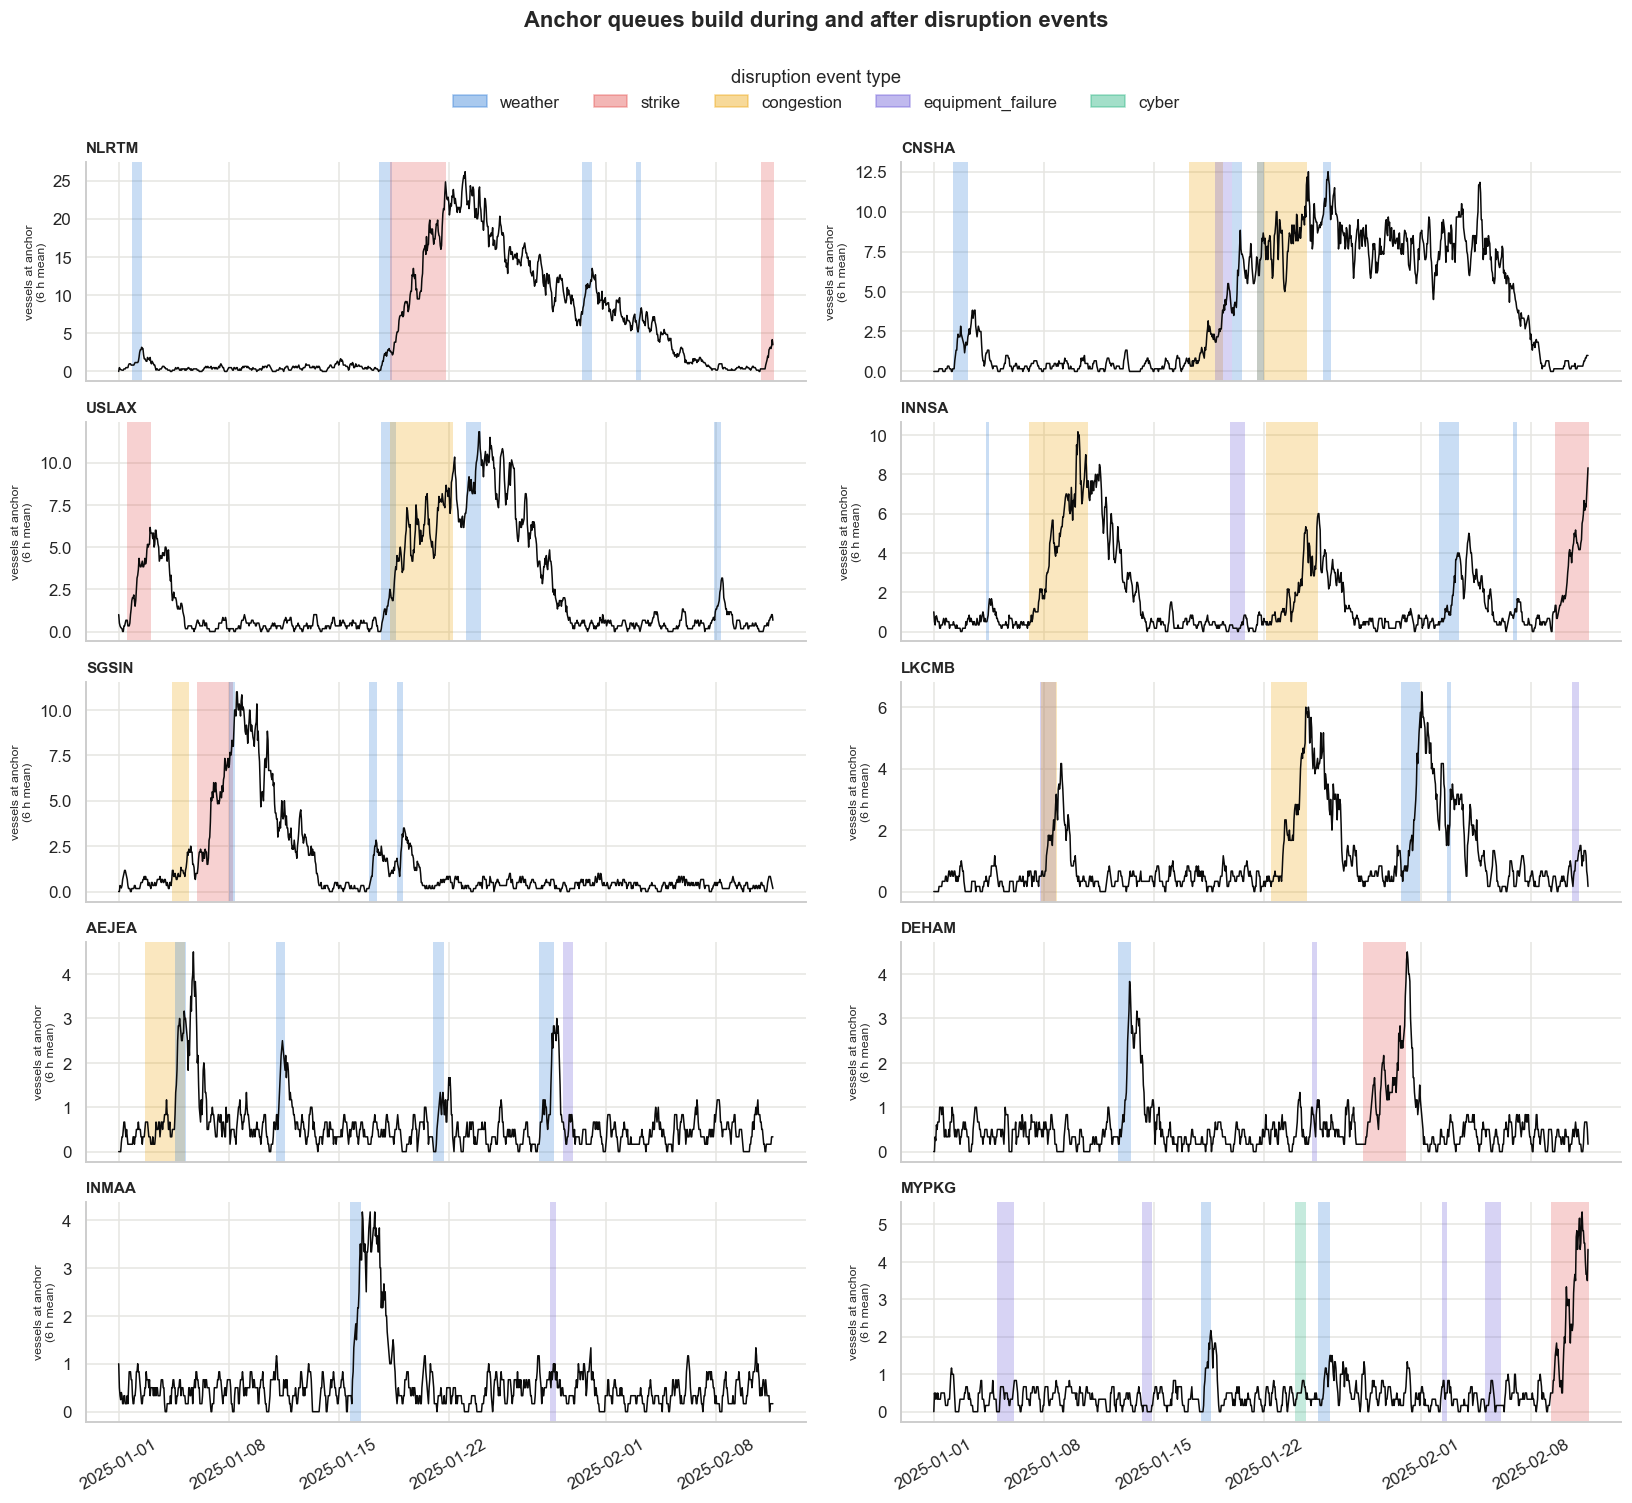

In [7]:
fig, axes = plt.subplots(5, 2, figsize=(15, 13), sharex=True)
ev_col = {"weather": "#2a78d6", "strike": "#e34948", "congestion": "#eda100", "equipment_failure": "#6250d6", "cyber": "#1baf7a"}
for ax, p in zip(axes.flat, prof.sort_values("p95_vessels_at_anchor", ascending=False).index):
    g = tel[tel.port_id == p].set_index("ts_hour")
    ax.plot(g.index, g.vessels_at_anchor.rolling(6, min_periods=1).mean(), color="#0b0b0b", lw=1)
    for _, e in dis[dis.port_id == p].iterrows():
        ax.axvspan(e.event_start, e.event_end, color=ev_col[e.event_type], alpha=0.25, lw=0)
    ax.set_title(p, loc="left", fontsize=10)
    ax.set_ylabel("vessels at anchor\n(6 h mean)", fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.4) for c in ev_col.values()]
fig.legend(handles, ev_col.keys(), loc="upper center", ncol=5, title="disruption event type", bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Anchor queues build during and after disruption events", y=1.05, fontweight="semibold")
for ax in axes[-1]:
    ax.tick_params(axis="x", rotation=30)
P.save(fig, "04_anchor_timeseries_with_disruptions")

In [8]:
# Quantify: port conditions inside vs outside disruption intervals (within port)
inside = np.zeros(len(tel), bool)
for _, e in dis.iterrows():
    inside |= ((tel.port_id == e.port_id) & (tel.ts_hour >= e.event_start) & (tel.ts_hour < e.event_end)).values
within["in_disruption"] = inside
cmp = within.groupby("in_disruption")[["vessels_at_anchor", "container_dwell_hours", "port_utilization_pct", "equipment_availability_pct", "customs_hold_hours"]].mean().T
cmp.columns = ["outside events", "inside events"]
cmp["cliffs_delta_inside_vs_outside"] = [stats.cliffs_delta(within.loc[inside, c], within.loc[~inside, c]) for c in cmp.index]
print(f"port-hours inside a disruption: {inside.sum()} ({inside.mean()*100:.1f}%)")
cmp.round(3)

port-hours inside a disruption: 1479 (14.8%)


,outside events,inside events,cliffs_delta_inside_vs_outside
vessels_at_anchor,-0.284,1.634,0.384
container_dwell_hours,-1.146,6.603,0.396
port_utilization_pct,4.205,-24.23,-0.866
equipment_availability_pct,0.506,-2.917,-0.145
customs_hold_hours,-0.041,0.238,0.009


**Reading:** during events, ports lose throughput (utilization falls — utilization here is *realised* throughput / nominal
capacity, not demand), equipment availability drops and vessels queue at anchor; dwell rises with a lag after the event.
This matters for interpretation below: **low utilization can indicate a disrupted port**, not a quiet one.

## D4. Origin and destination conditions before departure vs delay class

In [9]:
f = features.build_shipment_features(lag_hours=1, tables=T)
sea = f[f.shipping_mode == "sea"].copy()
port_feats = [
    "o_port_utilization_pct", "o_util_mean24", "o_util_max24", "o_util_change24", "o_vessels_at_anchor", "o_anchor_mean24", "o_anchor_max24",
    "o_container_dwell_hours", "o_dwell_mean24", "o_vessel_time_in_port_hours", "o_customs_hold_hours", "o_customs_mean24",
    "o_equipment_availability_pct", "o_equip_min24", "o_labour_disrupted_share24", "o_arrivals_sum24", "o_throughput_teu",
    "d_port_utilization_pct", "d_util_mean24", "d_vessels_at_anchor", "d_anchor_mean24", "d_container_dwell_hours", "d_customs_hold_hours",
    "d_equipment_availability_pct", "d_labour_disrupted_share24",
    "h_util_mean24", "h_anchor_mean24", "h_container_dwell_hours", "h_labour_disrupted_share24",
]
pt = stats.screen_numeric(sea, port_feats)
pt["magnitude_Crit_vs_OnTime"] = pt["cliff_Critical_vs_On-Time"].map(stats.magnitude_label)
pt = pt.sort_values("epsilon_sq", ascending=False)
P.save_table(pt, "04_port_features_vs_class")
pt[["n", "epsilon_sq", "median_On-Time", "median_At-Risk", "median_Critical", "cliff_At-Risk_vs_On-Time", "cliff_Critical_vs_On-Time", "cliff_Critical_vs_At-Risk", "spearman_rho_delay_h", "magnitude_Crit_vs_OnTime"]].round(3)

,n,epsilon_sq,median_On-Time,median_At-Risk,median_Critical,cliff_At-Risk_vs_On-Time,cliff_Critical_vs_On-Time,cliff_Critical_vs_At-Risk,spearman_rho_delay_h,magnitude_Crit_vs_OnTime
feature,,,,,,,,,,
o_anchor_mean24,9347,0.129,0.417,0.667,1.917,0.309,0.54,0.238,0.39,large
o_anchor_max24,9347,0.128,2,3,5,0.293,0.526,0.235,0.383,large
o_vessels_at_anchor,9347,0.117,0,1,3,0.247,0.504,0.261,0.361,large
o_container_dwell_hours,9347,0.075,77.6,87.7,100.7,0.19,0.435,0.254,0.272,medium
o_dwell_mean24,9347,0.072,76.55,88.94,101.3,0.204,0.419,0.226,0.273,medium
o_vessel_time_in_port_hours,9347,0.045,23.6,25.2,27,0.171,0.326,0.161,0.218,small
h_util_mean24,3479,0.02,68.67,73.2,75.91,0.153,0.183,0.03,0.162,small
o_util_max24,9347,0.017,89.51,94.39,96.37,0.157,0.128,-0.003,0.14,negligible
o_port_utilization_pct,9347,0.017,74.96,77.68,66.25,0.083,-0.168,-0.206,-0.027,small


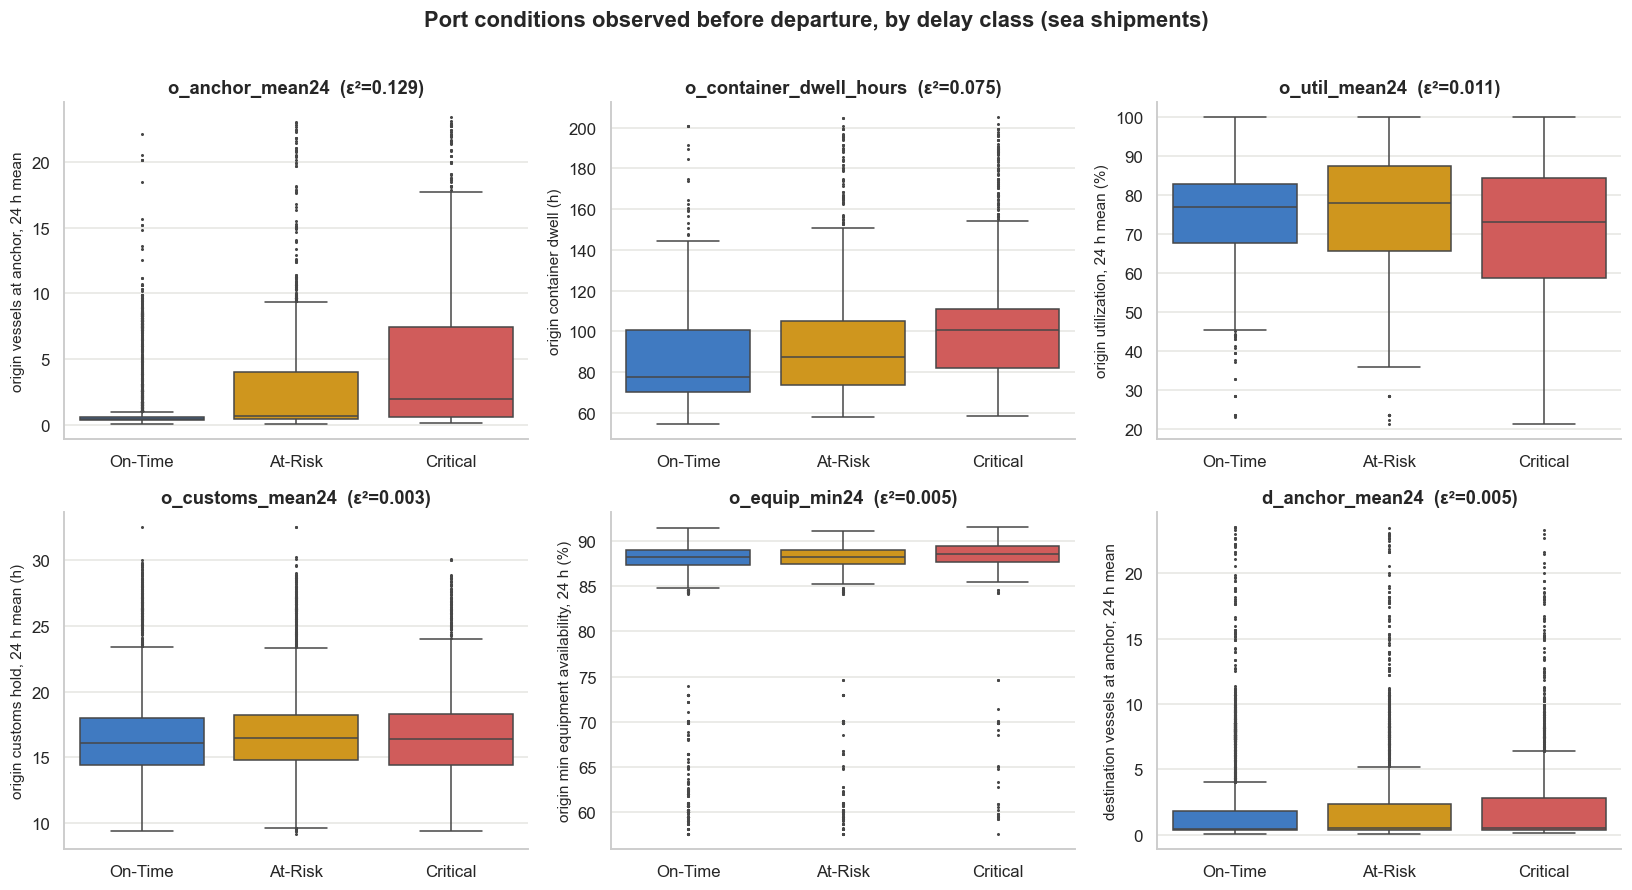

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c, lab in zip(axes.flat,
                      ["o_anchor_mean24", "o_container_dwell_hours", "o_util_mean24", "o_customs_mean24", "o_equip_min24", "d_anchor_mean24"],
                      ["origin vessels at anchor, 24 h mean", "origin container dwell (h)", "origin utilization, 24 h mean (%)",
                       "origin customs hold, 24 h mean (h)", "origin min equipment availability, 24 h (%)", "destination vessels at anchor, 24 h mean"]):
    sns.boxplot(data=sea, x="delay_status", y=c, hue="delay_status", legend=False, order=CLASSES, palette=CLASS_COLORS, ax=ax, fliersize=1, linewidth=1)
    ax.set_xlabel("")
    ax.set_ylabel(lab)
    ax.set_title(f"{c}  (ε²={pt.loc[c, 'epsilon_sq']:.3f})")
fig.suptitle("Port conditions observed before departure, by delay class (sea shipments)", y=1.01, fontweight="semibold")
P.save(fig, "04_port_conditions_by_class")

### Dose–response: delay class mix by origin anchorage congestion

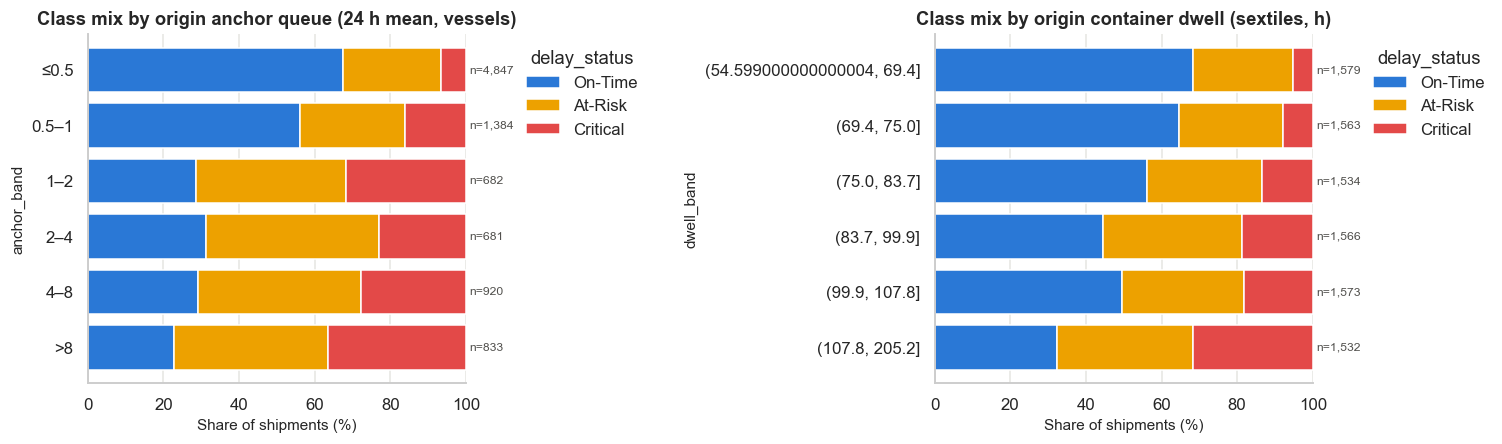

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sea["anchor_band"] = pd.cut(sea.o_anchor_mean24, [-0.01, 0.5, 1, 2, 4, 8, 100], labels=["≤0.5", "0.5–1", "1–2", "2–4", "4–8", ">8"])
P.stacked_class_bar(sea, "anchor_band", ax=axes[0], order=["≤0.5", "0.5–1", "1–2", "2–4", "4–8", ">8"], title="Class mix by origin anchor queue (24 h mean, vessels)")
sea["dwell_band"] = pd.qcut(sea.o_container_dwell_hours, 6)
P.stacked_class_bar(sea, "dwell_band", ax=axes[1], order=sorted(sea.dwell_band.dropna().unique()), title="Class mix by origin container dwell (sextiles, h)")
P.save(fig, "04_dose_response_anchor_dwell")

### Is the relationship consistent across ports?
Per-origin-port Spearman ρ between each condition and delay hours. A relation that holds within most ports is not just a
between-port difference.

,n,o_anchor_mean24,o_container_dwell_hours,o_util_mean24,o_customs_mean24,o_equip_min24,o_vessel_time_in_port_hours
origin_port_id,,,,,,,
AEJEA,892,0.29,0.18,-0.16,0.03,0.01,0.07
CNSHA,2080,0.41,0.38,-0.11,-0.06,0.15,0.25
DEHAM,670,0.09,0.03,-0.05,0.1,-0.01,0.09
INMAA,409,0.21,0,0,0.13,-0.02,0.07
INNSA,579,0.31,0.25,-0.21,0.1,0.03,0.13
LKCMB,630,0.26,0.19,0.02,0.12,0.11,0.09
MYPKG,851,0.23,0.11,-0.11,0.21,0.01,0.08
NLRTM,821,0.49,0.46,-0,-0.09,0.14,0.38
SGSIN,1673,0.32,0.27,-0,-0.02,-0.09,0.14


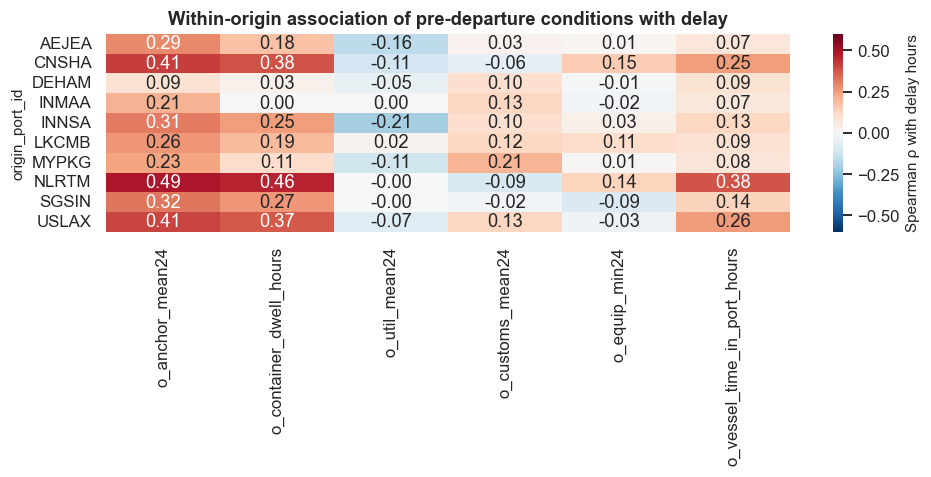

In [12]:
rows = []
for p, g in sea.groupby("origin_port_id"):
    row = {"origin_port_id": p, "n": len(g)}
    for c in ["o_anchor_mean24", "o_container_dwell_hours", "o_util_mean24", "o_customs_mean24", "o_equip_min24", "o_vessel_time_in_port_hours"]:
        row[c] = ss.spearmanr(g[c], g.actual_delay_hours)[0]
    rows.append(row)
per_port = pd.DataFrame(rows).set_index("origin_port_id")
P.save_table(per_port, "04_per_port_spearman")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(per_port.drop(columns="n"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, ax=ax, cbar_kws={"label": "Spearman ρ with delay hours"})
ax.set_title("Within-origin association of pre-departure conditions with delay")
P.save(fig, "04_per_port_spearman")
per_port.round(2)

### Customs hold vs shipment delay

In [13]:
print("Spearman(o_customs_hold_hours, delay):", round(ss.spearmanr(sea.o_customs_hold_hours, sea.actual_delay_hours)[0], 3))
print("Spearman(d_customs_hold_hours, delay):", round(ss.spearmanr(sea.d_customs_hold_hours, sea.actual_delay_hours)[0], 3))
print("Within-port Spearman(customs_hold, anchor):", round(ss.spearmanr(within.customs_hold_hours, within.vessels_at_anchor)[0], 3),
      "| (customs_hold, dwell):", round(ss.spearmanr(within.customs_hold_hours, within.container_dwell_hours)[0], 3))

Spearman(o_customs_hold_hours, delay): 0.014
Spearman(d_customs_hold_hours, delay): -0.036
Within-port Spearman(customs_hold, anchor): 0.026 | (customs_hold, dwell): 0.031


## D5. Findings — port operations

* **Anchorage congestion at the origin is the strongest port-operations signal.** The 24 h mean vessels-at-anchor has
  median 0.42 (On-Time) → 0.67 (At-Risk) → 1.92 (Critical); ε² = 0.13, Cliff's δ Critical vs On-Time = 0.54 (large),
  At-Risk vs On-Time = 0.31. The within-origin Spearman ρ with delay hours is positive at all 10 origins (0.09 DEHAM to 0.49 NLRTM).
* **Container dwell and vessel time in port at origin** come next (dwell median 78 → 88 → 101 h; δ = 0.44). Both rise during
  and after disruption events (dwell δ inside vs outside events = 0.40).
* **Utilization is not a simple congestion measure.** It is realised throughput / nominal capacity, capped at 100 %. It
  *falls* when capacity is lost (within-port mean −24 pp during events, −38 pp during strikes). The current-hour value is
  therefore *lower* for Critical shipments (66 % vs 75 %) while the 24 h maximum is higher (96 % vs 90 %). The relationship to
  risk is non-monotonic. Feature engineering should pair utilization with queue length (backlog) rather than read it as
  "busy = risky".
* **Customs hold time** has no meaningful association with delay (ρ = 0.01 origin, −0.04 destination) and is unrelated to
  anchor queue or dwell within port. That is a negative result. Customs hold is longer under *reduced* labour (+6.9 h vs port mean).
  Note: 500 customs values were filled during cleaning (notebook 01).
* **Equipment availability** shows essentially **no** within-port correlation with utilization/throughput (per-port ρ between
  −0.05 and 0.13). It dips only slightly during disruption events (δ = −0.15) and its 24 h minimum carries negligible signal
  for delay (ε² = 0.005). The expected "equipment → throughput" link is not visible in this data.
* **Labour status** (reduced / strike) coincides with longer anchor queues (+2.9 vessels during strikes), longer dwell
  (+12 h) and much lower utilization within port.
* **Destination conditions at departure time** are weakly informative (ε² ≤ 0.008). The vessel reaches the destination
  days later, so destination state now is a poor proxy for its state on arrival (which is future information, notebook 09).
* **Transshipment hub utilization** (h_util_mean24, ε² = 0.02) carries some signal for the 37 % of shipments with a hub.

All associations are observational. Port congestion and delays may share common causes (disruptions, weather), see notebook 08.